# Predator: predicting online purchases and explaining why

**Question:** will an online shopping session end in a purchase, and which behaviours drive that prediction?

We use the **Online Shoppers Purchasing Intention** dataset (UCI / Kaggle): 12,330 browsing sessions from an online store, each described by 17 features (pages visited, time spent, Google Analytics metrics such as bounce rate, exit rate and page value, plus month, visitor type and technical details). The target `Revenue` says whether the session ended in a purchase; only about 15% did.

**Models**
- Main models: **Decision Tree** and **K-Nearest Neighbours** (KNN, trained with and without undersampling)
- Baseline: **Gaussian Naive Bayes**
- Benchmark beyond the main models: **XGBoost**

**What this notebook covers:** data checks and EDA, a leak-free preprocessing pipeline, tuning with 5-fold stratified cross-validation, test-set evaluation, feature importance, an ablation without `PageValues`, a profit-based decision threshold, and an error analysis of the sessions the best model gets wrong.

> This walkthrough imports the code from the `predator/` package. Run `python main.py` for the same pipeline in one command, and `streamlit run app.py` for the demo app.

In [1]:
import os
import warnings

import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def show(path, width=900):
    """Display a saved figure inside the notebook."""
    display(Image(filename=path, width=width))

# Run from the project folder so data/ and outputs/ are found.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working folder:", os.getcwd())

Working folder: /home/user/Predator


## 1. Loading and checking the data

`find_dataset()` looks in a local `data/` folder first and then searches `/kaggle/input/`, so the same code runs on a laptop and on Kaggle. We then check for missing values, duplicates and negative numbers.

In [2]:
from predator.data import find_dataset, load_dataset, validate_dataset, split_data, run_eda

dataset = load_dataset()
quality_report = validate_dataset(dataset)
dataset.head()

Loading dataset from: data/online_shoppers_intention.csv

Checking data quality...
  Rows (sessions): 12330
  Feature columns: 17
  Missing values: 0
  Duplicate rows: 125
  Sessions that ended in a purchase: 15.5%
  Note: duplicate rows are kept, they are mostly identical one-page visits.
  Negative values in numerical columns: 0


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,0


## 2. Exploratory data analysis

Four questions: how imbalanced is the target, how do the numerical features differ between buyers and non-buyers, which categories buy more often, and which features move together?


Drawing EDA plots...


  Saved outputs/figures/class_balance.png
  Saved outputs/figures/numerical_distributions.png
  Saved outputs/figures/categorical_purchase_rates.png
  Saved outputs/figures/correlation_heatmap.png


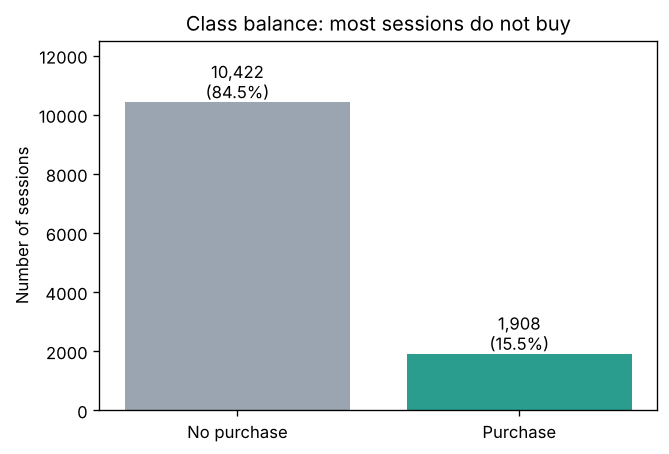

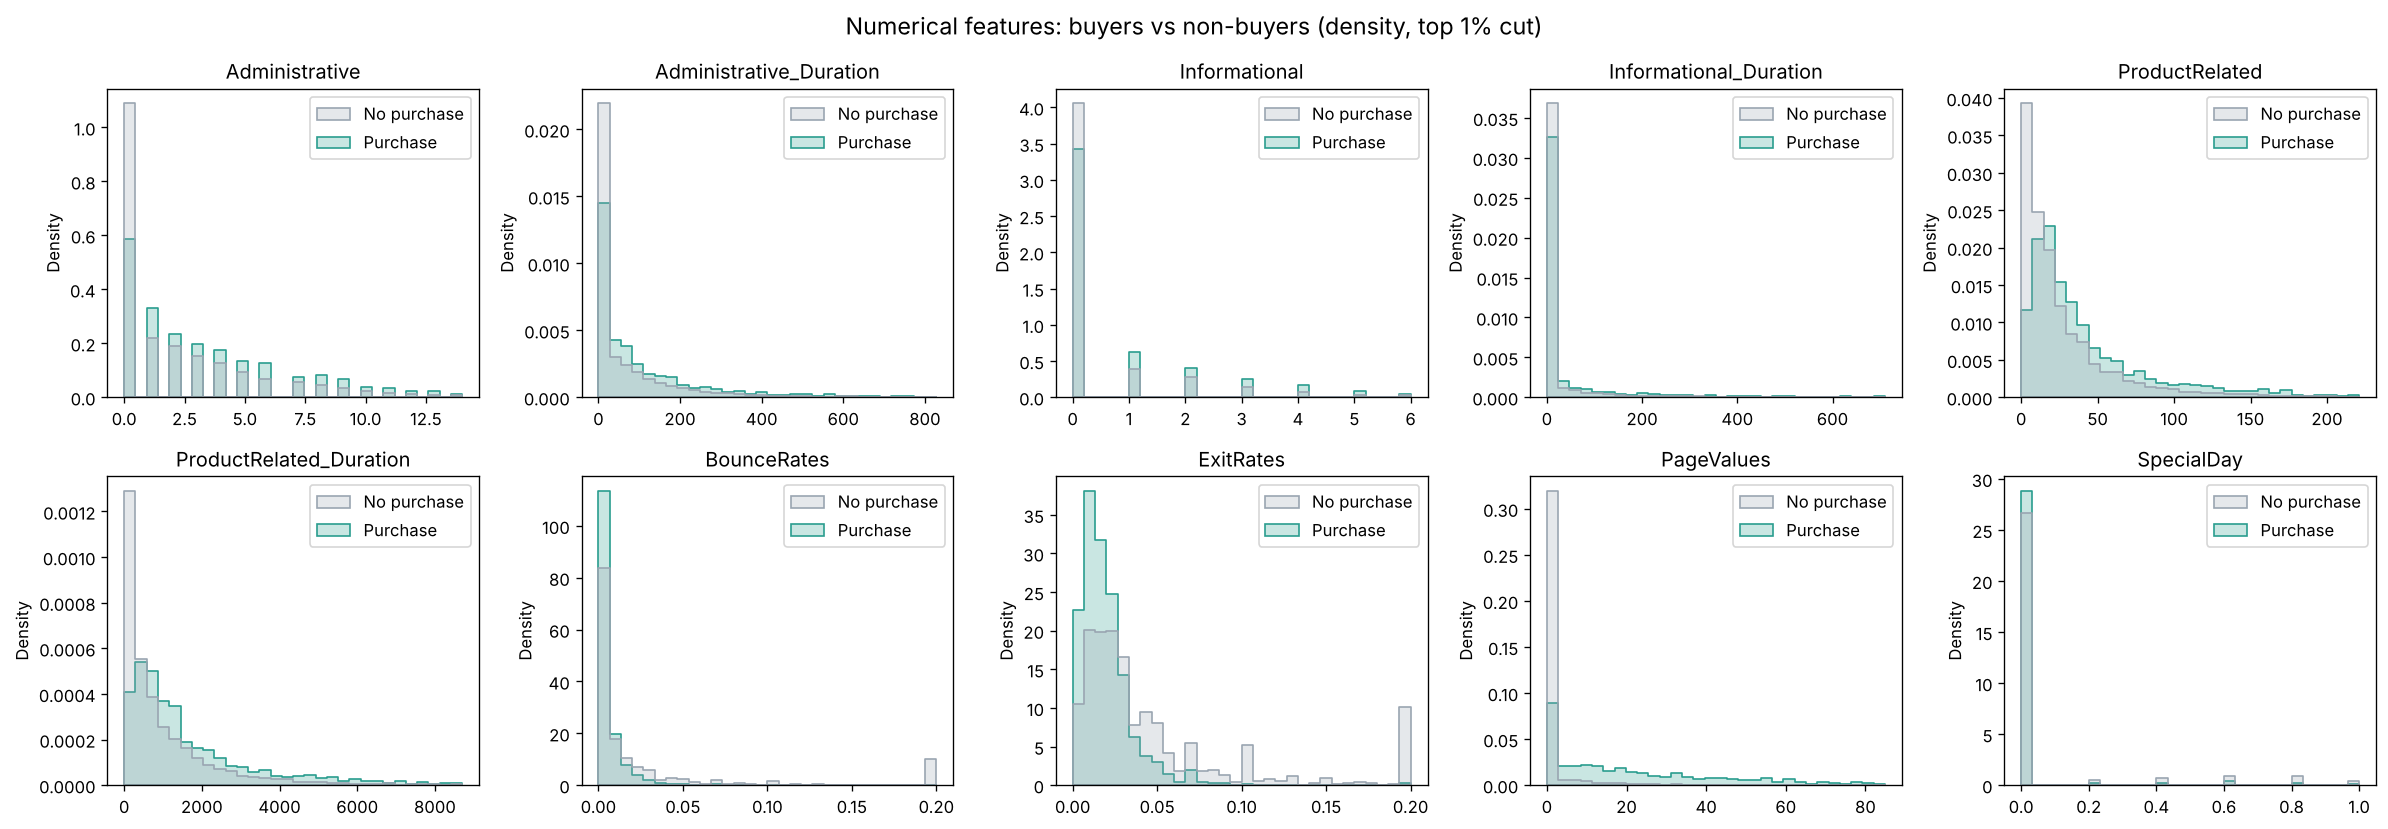

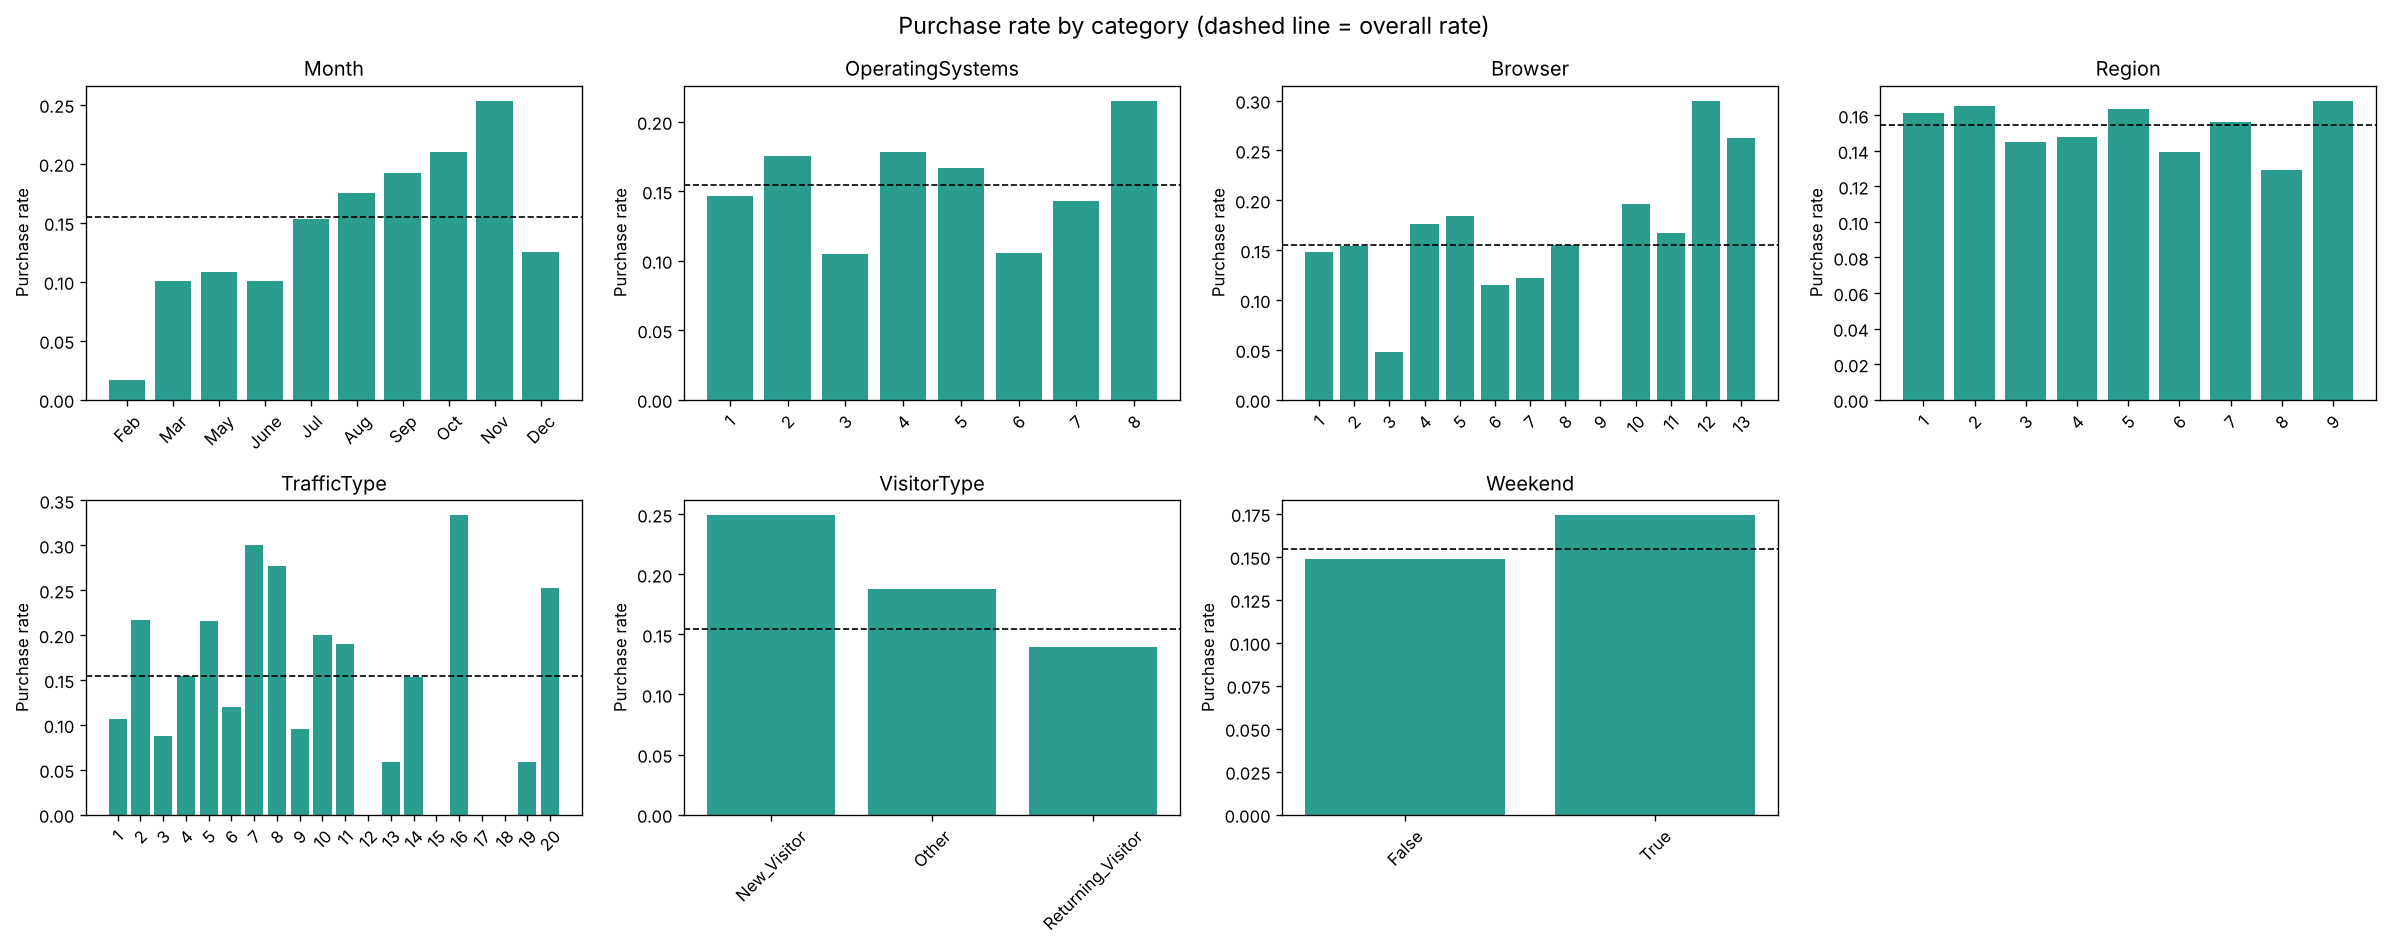

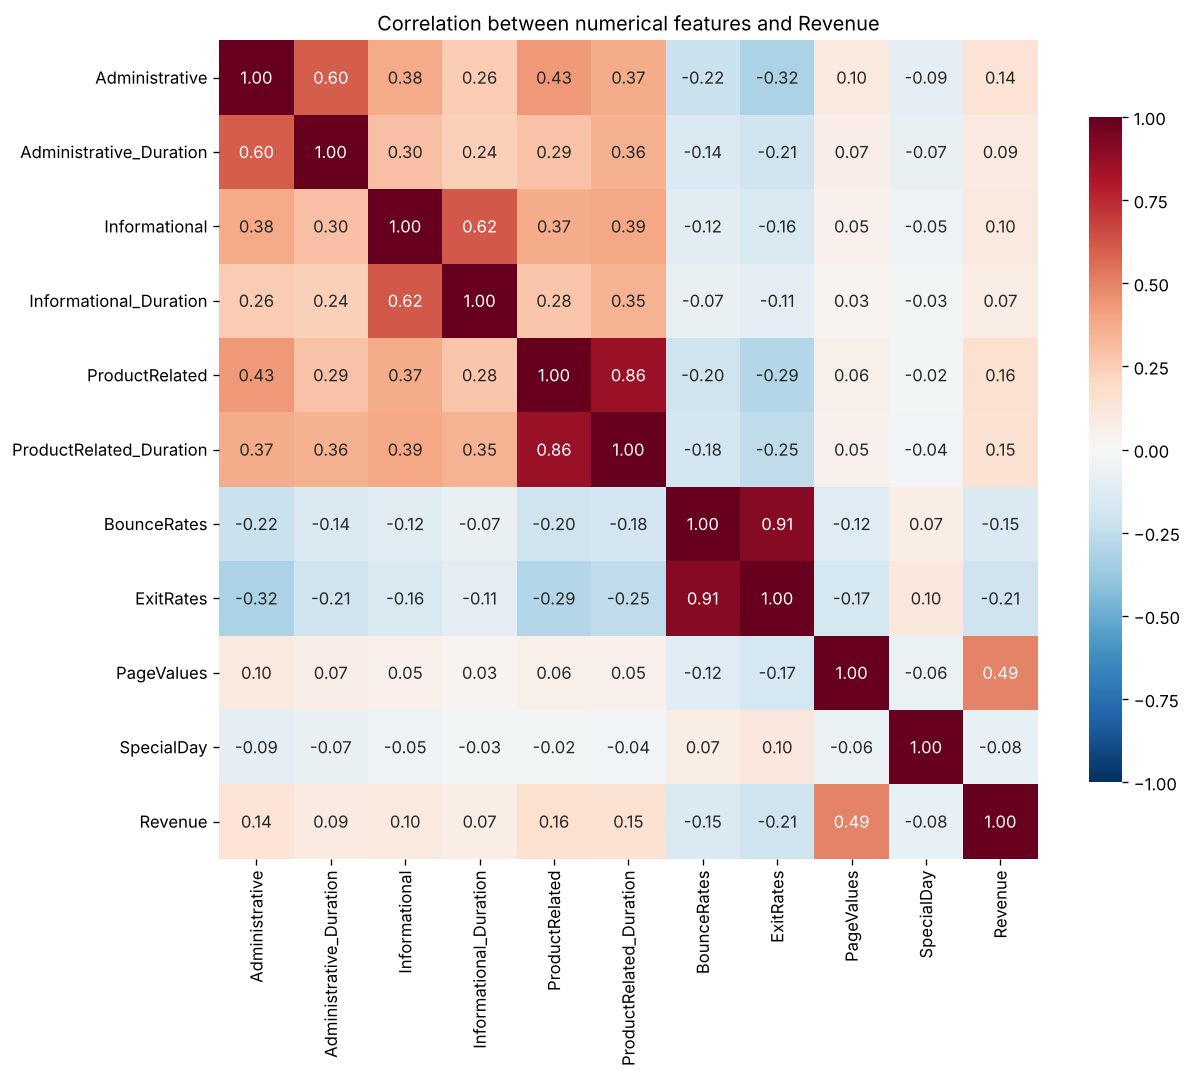

In [3]:
figure_paths = run_eda(dataset)
for path in figure_paths:
    show(path)

**What the EDA shows**

- Only about 15% of sessions buy. A model that always says "no purchase" is 85% accurate and useless, so we judge models with **precision, recall, F1 and ROC-AUC** instead of accuracy.
- **PageValues** separates the classes most clearly: most non-buyers have a page value of 0, most buyers do not. It is also the numerical feature most correlated with `Revenue`.
- **BounceRates and ExitRates** are strongly correlated with each other, and both are higher for non-buyers.
- **November** has the highest purchase rate, and new visitors buy more often than returning ones.
- The duration features are very skewed (many zeros, a long tail), which matters for distance-based KNN.

## 3. Train/test split and preprocessing

We split 80/20, **stratified** so both parts keep the 15% buyer rate, with `random_state=42` everywhere for reproducibility. The test set is put aside until the final evaluation.

Preprocessing lives inside a scikit-learn `Pipeline` with a `ColumnTransformer`:
- categorical columns (Month, VisitorType, codes such as Browser) are **one-hot encoded**;
- numerical columns are **standardised** for KNN and Naive Bayes (KNN compares distances, so a duration in thousands of seconds would otherwise drown out a rate between 0 and 0.2). Tree models do not need scaling, so we keep their numbers in real units, which keeps the tree's split rules readable.

Because the scaler and encoder are fitted inside the pipeline, they only ever see training data, even inside each cross-validation fold. That prevents **data leakage**.

In [4]:
from predator.preprocess import build_pipeline, get_feature_names, undersample_training_data

train_features, test_features, train_target, test_target = split_data(dataset)


Split the data (stratified 80/20):
  Training sessions: 9864 (buyers: 15.5%)
  Test sessions:     2466 (buyers: 15.5%)


## 4. The models and their hyperparameter grids

- **Decision Tree**: asks yes/no questions, choosing at each step the split that lowers Gini impurity or entropy the most. `class_weight="balanced"` makes errors on the rare buyer class count more.
- **KNN**: classifies a session by a vote of its k most similar training sessions (Euclidean or Manhattan distance). It has no class weights, so we also train a version on **randomly undersampled** training data (all buyers plus an equal number of non-buyers).
- **Gaussian Naive Bayes**: applies Bayes' theorem assuming features are independent and bell-shaped within each class. Neither assumption holds here, which makes it a useful untuned baseline.
- **XGBoost (benchmark)**: gradient boosting; each new small tree is trained to fix the errors of the trees before it. `scale_pos_weight` (non-buyers / buyers) handles the imbalance.

In [5]:
from predator.models import MODEL_NAMES, DECISION_TREE, XGBOOST, get_parameter_grids

for model_name, grid in get_parameter_grids().items():
    print(model_name, "->", grid if grid else "no tuning (baseline)")

Decision Tree -> {'model__max_depth': [3, 5, 7, 10, 15, None], 'model__min_samples_split': [2, 10, 20, 50], 'model__min_samples_leaf': [1, 5, 10, 20], 'model__criterion': ['gini', 'entropy']}
KNN -> {'model__n_neighbors': [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31], 'model__weights': ['uniform', 'distance'], 'model__metric': ['euclidean', 'manhattan']}
KNN (undersampled) -> {'model__n_neighbors': [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31], 'model__weights': ['uniform', 'distance'], 'model__metric': ['euclidean', 'manhattan']}
Naive Bayes (baseline) -> no tuning (baseline)
XGBoost (benchmark) -> {'model__n_estimators': [100, 200, 300], 'model__max_depth': [3, 4, 5, 6], 'model__learning_rate': [0.03, 0.1, 0.3]}


## 5. Tuning with 5-fold stratified cross-validation

`GridSearchCV` tries every combination in each grid, training on 4 folds and scoring F1 on the 5th, and keeps the best average. Afterwards we compute **out-of-fold** probabilities for every training session (each one predicted by a model that did not see it). These give a fair cross-validated F1 for every model on the real class balance, including the undersampled KNN, and they are what we later use to choose decision thresholds without touching the test set.

In [6]:
from predator.train import train_all_models, save_models

training_results = train_all_models(train_features, train_target)
models = {name: result["pipeline"] for name, result in training_results.items()}


Training Decision Tree...
  Trying 192 combinations x 5 folds


  Best settings: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 20, 'min_samples_split': 50}
  Cross-validated F1 (real class balance): 0.642
  Took 15.8 seconds

Training KNN...
  Trying 64 combinations x 5 folds


  Best settings: {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'distance'}
  Cross-validated F1 (real class balance): 0.493
  Took 27.9 seconds

Training KNN (undersampled)...
  Undersampled training set: 3052 sessions (50% buyers)
  Trying 64 combinations x 5 folds


  Best settings: {'metric': 'manhattan', 'n_neighbors': 27, 'weights': 'distance'}
  Cross-validated F1 (real class balance): 0.521
  Took 4.6 seconds

Training Naive Bayes (baseline)...
  Cross-validated F1 (real class balance): 0.299
  Took 0.2 seconds

Training XGBoost (benchmark)...
  Trying 36 combinations x 5 folds


  Best settings: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 100}
  Cross-validated F1 (real class balance): 0.673
  Took 15.0 seconds


## 6. Evaluation on the test set

Every model is scored once on the untouched test set at the default 0.5 threshold. The best model is chosen by **cross-validated F1** (choosing by test score would quietly tune on the test set).


Evaluating models on the test set (threshold 0.5)...
Decision Tree
Confusion matrix (rows = actual, columns = predicted):
                 No purchase  Purchase
  No purchase           1791       293
  Purchase                74       308

              precision    recall  f1-score   support

 No purchase      0.960     0.859     0.907      2084
    Purchase      0.512     0.806     0.627       382

    accuracy                          0.851      2466
   macro avg      0.736     0.833     0.767      2466
weighted avg      0.891     0.851     0.864      2466


KNN
Confusion matrix (rows = actual, columns = predicted):
                 No purchase  Purchase
  No purchase           1973       111
  Purchase               231       151

              precision    recall  f1-score   support

 No purchase      0.895     0.947     0.920      2084
    Purchase      0.576     0.395     0.469       382

    accuracy                          0.861      2466
   macro avg      0.736     0.671   

Naive Bayes (baseline)
Confusion matrix (rows = actual, columns = predicted):
                 No purchase  Purchase
  No purchase            301      1783
  Purchase                10       372

              precision    recall  f1-score   support

 No purchase      0.968     0.144     0.251      2084
    Purchase      0.173     0.974     0.293       382

    accuracy                          0.273      2466
   macro avg      0.570     0.559     0.272      2466
weighted avg      0.845     0.273     0.258      2466


XGBoost (benchmark)
Confusion matrix (rows = actual, columns = predicted):
                 No purchase  Purchase
  No purchase           1832       252
  Purchase                80       302

              precision    recall  f1-score   support

 No purchase      0.958     0.879     0.917      2084
    Purchase      0.545     0.791     0.645       382

    accuracy                          0.865      2466
   macro avg      0.752     0.835     0.781      2466
weighted av

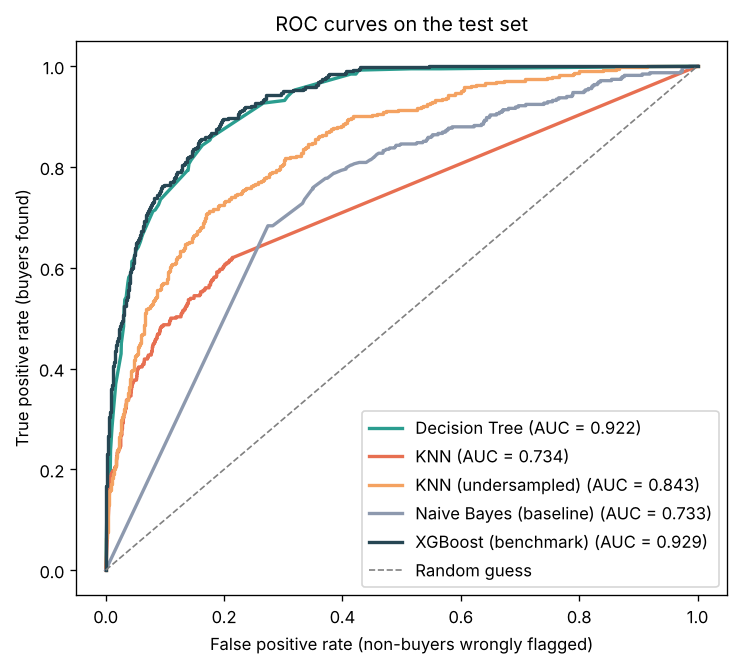

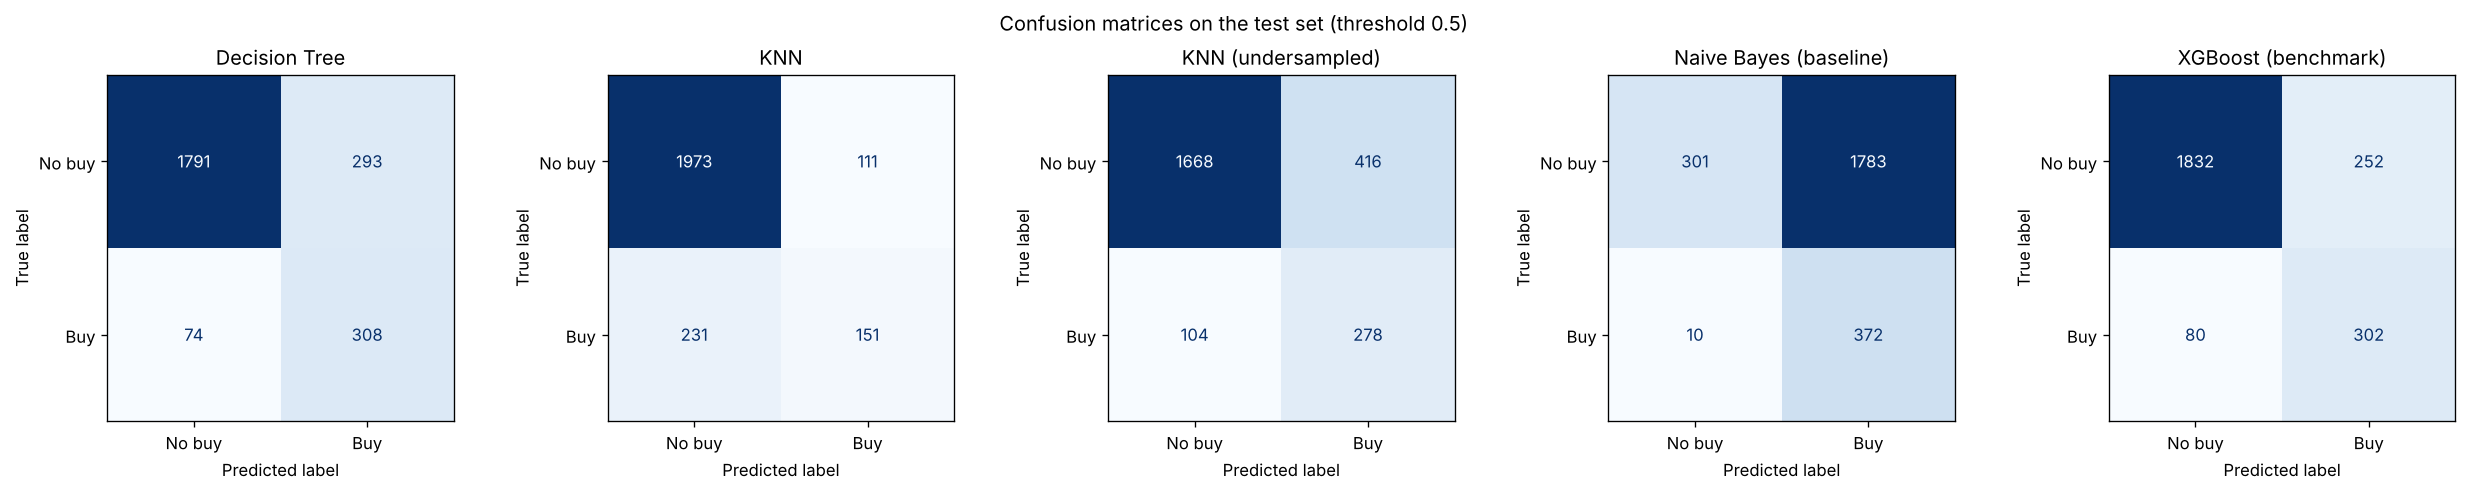

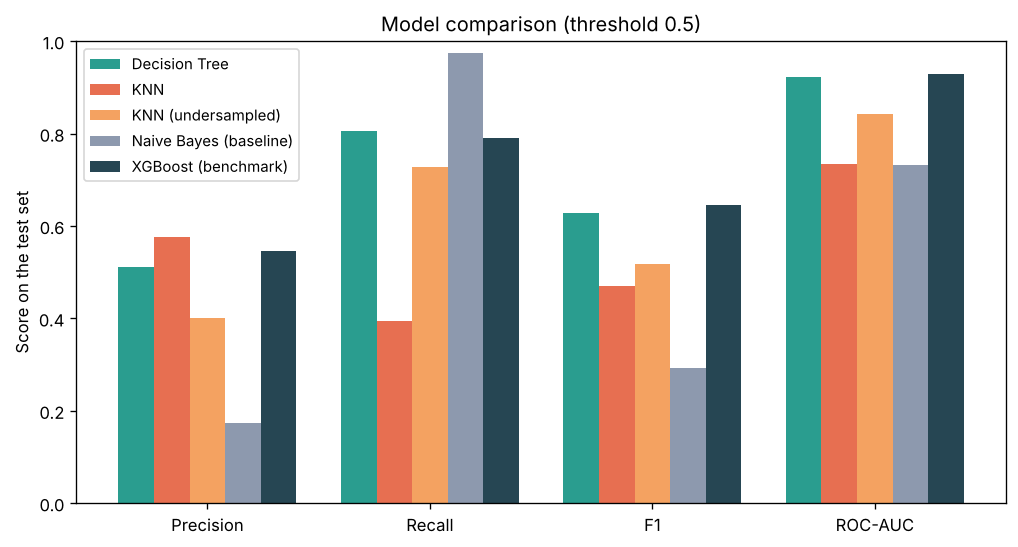

,Model,Role,CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
0,Decision Tree,Main (course),0.642,0.851,0.512,0.806,0.627,0.922
1,KNN,Main (course),0.493,0.861,0.576,0.395,0.469,0.734
2,KNN (undersampled),Main (course),0.521,0.789,0.401,0.728,0.517,0.843
3,Naive Bayes (baseline),Baseline,0.299,0.273,0.173,0.974,0.293,0.733
4,XGBoost (benchmark),Benchmark (beyond course),0.673,0.865,0.545,0.791,0.645,0.929


In [7]:
from predator.evaluate import build_comparison_table, choose_best_model, plot_roc_curves, plot_confusion_matrices, plot_metric_comparison

comparison_table = build_comparison_table(models, training_results, test_features, test_target)
best_model_name = choose_best_model(comparison_table)
show(plot_roc_curves(models, test_features, test_target), width=600)
show(plot_confusion_matrices(models, test_features, test_target))
show(plot_metric_comparison(comparison_table), width=750)
comparison_table

**Reading the results**

- **XGBoost (benchmark)** and the **Decision Tree** are clearly ahead, with test ROC-AUC around 0.92 to 0.93. The tree gets most of the benchmark's performance.
- **KNN** struggles: with dozens of one-hot columns and skewed durations, "nearest" sessions are not very informative. Undersampling raises its recall a lot at the cost of precision, and improves its F1 and ROC-AUC.
- **Naive Bayes** flags almost every session as a buyer: its independence assumption breaks on correlated, skewed features, and its probabilities end up pushed to 0 or 1.

## 7. Which features drive the predictions?

Three views: the Decision Tree's own impurity-based importance, a picture of its top levels, and **permutation importance** for every model. Permutation importance shuffles one original column of the test set and measures how much ROC-AUC drops, so it works for any model and compares them on the same 17 features.

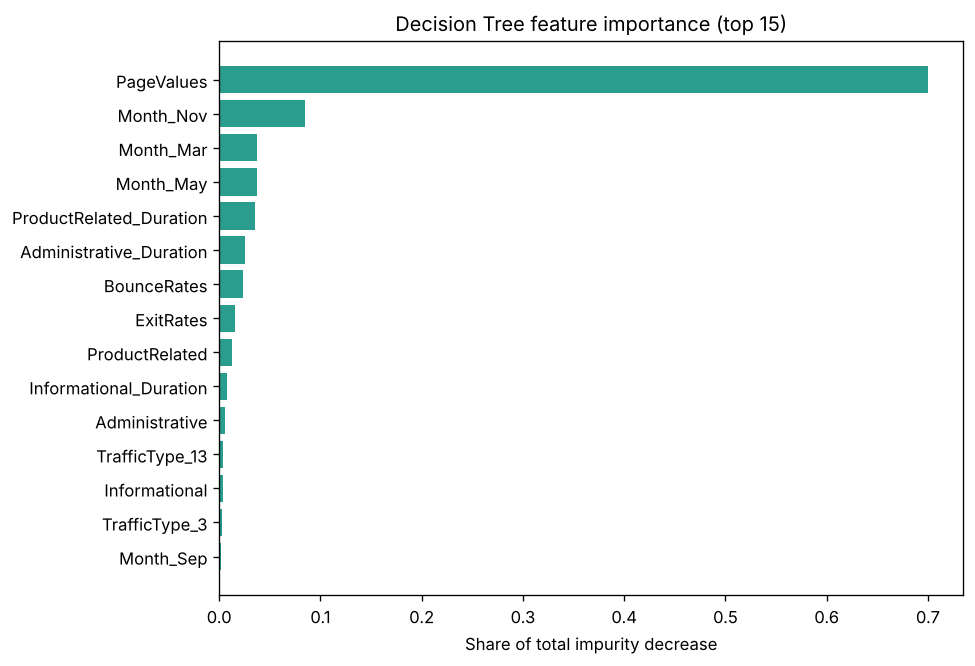

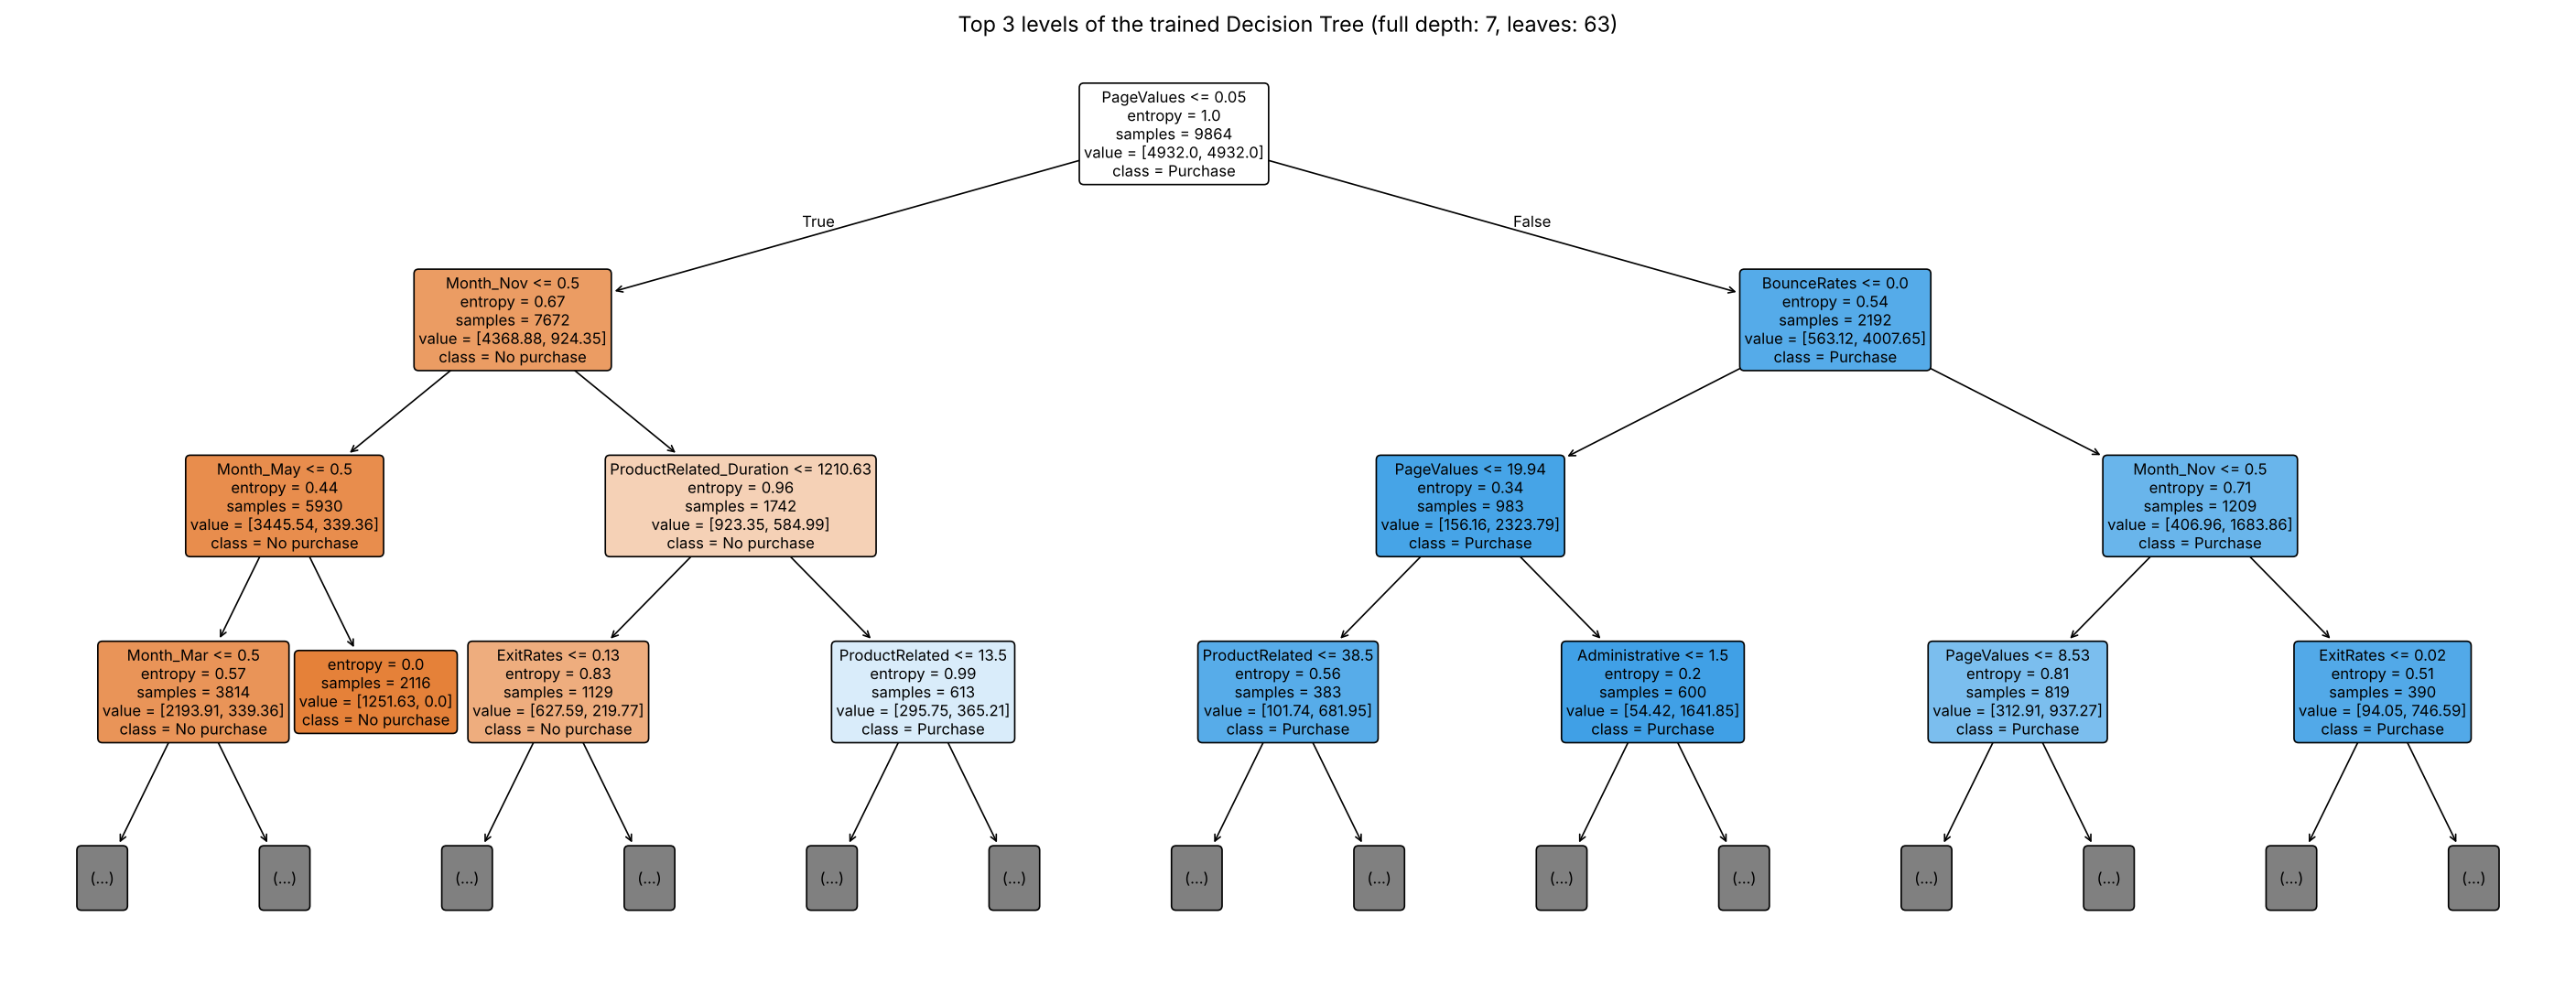


Computing permutation importance (this takes a minute)...
  Decision Tree


  KNN


  KNN (undersampled)


  Naive Bayes (baseline)


  XGBoost (benchmark)


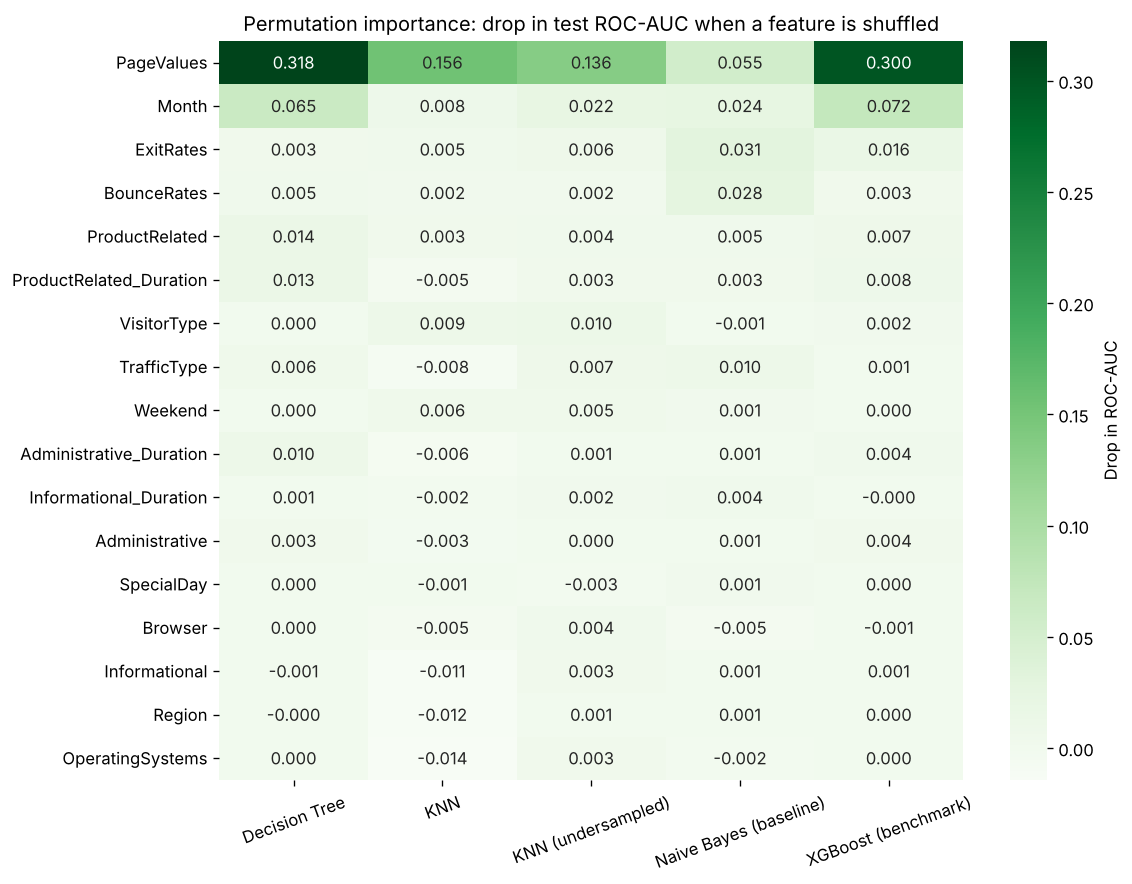

,Decision Tree,KNN,KNN (undersampled),Naive Bayes (baseline),XGBoost (benchmark)
PageValues,0.318,0.156,0.136,0.055,0.300
Month,0.065,0.008,0.022,0.024,0.072
ExitRates,0.003,0.005,0.006,0.031,0.016
BounceRates,0.005,0.002,0.002,0.028,0.003
ProductRelated,0.014,0.003,0.004,0.005,0.007
ProductRelated_Duration,0.013,-0.005,0.003,0.003,0.008
VisitorType,0.000,0.009,0.010,-0.001,0.002
TrafficType,0.006,-0.008,0.007,0.010,0.001
Weekend,0.000,0.006,0.005,0.001,0.000
Administrative_Duration,0.010,-0.006,0.001,0.001,0.004


In [8]:
from predator.explain import plot_tree_feature_importance, plot_top_of_tree, permutation_importance_all_models, write_tree_vs_xgboost_comparison, run_ablation

tree_importance = plot_tree_feature_importance(models[DECISION_TREE])
show("outputs/figures/tree_feature_importance.png", width=650)
show(plot_top_of_tree(models[DECISION_TREE], max_depth=3))
importance_table = permutation_importance_all_models(models, test_features, test_target)
show("outputs/figures/permutation_importance.png", width=750)
importance_table.round(3)

The tree's very first question is about **PageValues**, and permutation importance agrees across models: shuffling PageValues costs far more ROC-AUC than any other feature, with **Month** (November) second. Behaviour features like ExitRates and product-page time matter much less.

### Decision Tree vs XGBoost: performance versus interpretability

In [9]:
display(Markdown(write_tree_vs_xgboost_comparison(comparison_table, models, importance_table)))


# Decision Tree vs XGBoost (benchmark): performance vs interpretability

| | Decision Tree | XGBoost (benchmark) |
|---|---|---|
| Test F1 | 0.627 | 0.645 |
| Test ROC-AUC | 0.922 | 0.929 |
| Precision / Recall | 0.512 / 0.806 | 0.545 / 0.791 |
| Size | 1 tree, depth 7, 63 leaves | 100 trees, depth up to 6 |
| Top 3 features (permutation) | PageValues, Month, ProductRelated | PageValues, Month, ExitRates |

**Performance.** XGBoost scores +0.007 ROC-AUC and +0.018 F1 compared with the Decision Tree. Boosting combines many small trees, each one correcting the errors of the previous ones, so it ranks sessions more smoothly than a single tree, whose probabilities jump in steps (one value per leaf).

**Interpretability.** The Decision Tree can be read as a flowchart: every prediction follows one path of yes/no questions, which we can print for any session (the Streamlit app does this). XGBoost adds up 100 trees, so no single path explains a prediction; we need outside tools such as permut

# Decision Tree vs XGBoost (benchmark): performance vs interpretability

| | Decision Tree | XGBoost (benchmark) |
|---|---|---|
| Test F1 | 0.627 | 0.645 |
| Test ROC-AUC | 0.922 | 0.929 |
| Precision / Recall | 0.512 / 0.806 | 0.545 / 0.791 |
| Size | 1 tree, depth 7, 63 leaves | 100 trees, depth up to 6 |
| Top 3 features (permutation) | PageValues, Month, ProductRelated | PageValues, Month, ExitRates |

**Performance.** XGBoost scores +0.007 ROC-AUC and +0.018 F1 compared with the Decision Tree. Boosting combines many small trees, each one correcting the errors of the previous ones, so it ranks sessions more smoothly than a single tree, whose probabilities jump in steps (one value per leaf).

**Interpretability.** The Decision Tree can be read as a flowchart: every prediction follows one path of yes/no questions, which we can print for any session (the Streamlit app does this). XGBoost adds up 100 trees, so no single path explains a prediction; we need outside tools such as permutation importance to see what it relies on.

**Agreement.** Both models rely on the same main signal: the top features are PageValues, Month, ProductRelated for the tree and PageValues, Month, ExitRates for XGBoost.

**Verdict.** If the small gain in score matters more than being able to explain each decision, XGBoost is the stronger benchmark. For a shop team that needs to understand and trust the rules, the Decision Tree gives most of the performance with full transparency.


## 8. Ablation: what if PageValues did not exist?

PageValues is computed from earlier purchases on the site, so it is close to a "historical purchase" signal. To see how much the models depend on it, we drop it, retrain every model with the same grids and folds, and compare scores and feature rankings.


ABLATION: retraining every model without PageValues

Training Decision Tree...
  Trying 192 combinations x 5 folds


  Best settings: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 50}
  Cross-validated F1 (real class balance): 0.397
  Took 16.8 seconds

Training KNN...
  Trying 64 combinations x 5 folds


  Best settings: {'metric': 'euclidean', 'n_neighbors': 1, 'weights': 'uniform'}
  Cross-validated F1 (real class balance): 0.281
  Took 27.5 seconds

Training KNN (undersampled)...
  Undersampled training set: 3052 sessions (50% buyers)
  Trying 64 combinations x 5 folds


  Best settings: {'metric': 'manhattan', 'n_neighbors': 27, 'weights': 'uniform'}
  Cross-validated F1 (real class balance): 0.375
  Took 4.4 seconds

Training Naive Bayes (baseline)...
  Cross-validated F1 (real class balance): 0.298
  Took 0.2 seconds

Training XGBoost (benchmark)...
  Trying 36 combinations x 5 folds


  Best settings: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 200}
  Cross-validated F1 (real class balance): 0.427
  Took 12.9 seconds

Evaluating models on the test set (threshold 0.5)...
Decision Tree
Confusion matrix (rows = actual, columns = predicted):
                 No purchase  Purchase
  No purchase           1445       639
  Purchase               139       243

              precision    recall  f1-score   support

 No purchase      0.912     0.693     0.788      2084
    Purchase      0.276     0.636     0.384       382

    accuracy                          0.685      2466
   macro avg      0.594     0.665     0.586      2466
weighted avg      0.814     0.685     0.725      2466


KNN
Confusion matrix (rows = actual, columns = predicted):
                 No purchase  Purchase
  No purchase           1785       299
  Purchase               280       102

              precision    recall  f1-score   support

 No purchase      0.864     0.857     0.860      2084

XGBoost (benchmark)
Confusion matrix (rows = actual, columns = predicted):
                 No purchase  Purchase
  No purchase           1456       628
  Purchase               118       264

              precision    recall  f1-score   support

 No purchase      0.925     0.699     0.796      2084
    Purchase      0.296     0.691     0.414       382

    accuracy                          0.697      2466
   macro avg      0.610     0.695     0.605      2466
weighted avg      0.828     0.697     0.737      2466


Model comparison (test set):
                 Model                      Role  CV F1  Accuracy  Precision  Recall    F1  ROC-AUC
         Decision Tree             Main (course)  0.397     0.685      0.276   0.636 0.384    0.721
                   KNN             Main (course)  0.281     0.765      0.254   0.267 0.261    0.562
    KNN (undersampled)             Main (course)  0.375     0.586      0.235   0.738 0.356    0.723
Naive Bayes (baseline)                  Baseline  

... (2 outputs left out)

  KNN (undersampled)


  Naive Bayes (baseline)


  XGBoost (benchmark)



Feature rankings with and without PageValues:
                 Model                                                             Top 5 with all features                                                           Top 5 without PageValues
         Decision Tree PageValues, Month, ProductRelated, ProductRelated_Duration, Administrative_Duration             ExitRates, ProductRelated_Duration, ProductRelated, Month, BounceRates
                   KNN                                  PageValues, VisitorType, Month, Weekend, ExitRates                       Month, TrafficType, ExitRates, VisitorType, OperatingSystems
    KNN (undersampled)                              PageValues, Month, VisitorType, TrafficType, ExitRates                Month, VisitorType, ExitRates, ProductRelated_Duration, TrafficType
Naive Bayes (baseline)                              PageValues, ExitRates, BounceRates, Month, TrafficType                            ExitRates, BounceRates, Month, TrafficType, VisitorType
   

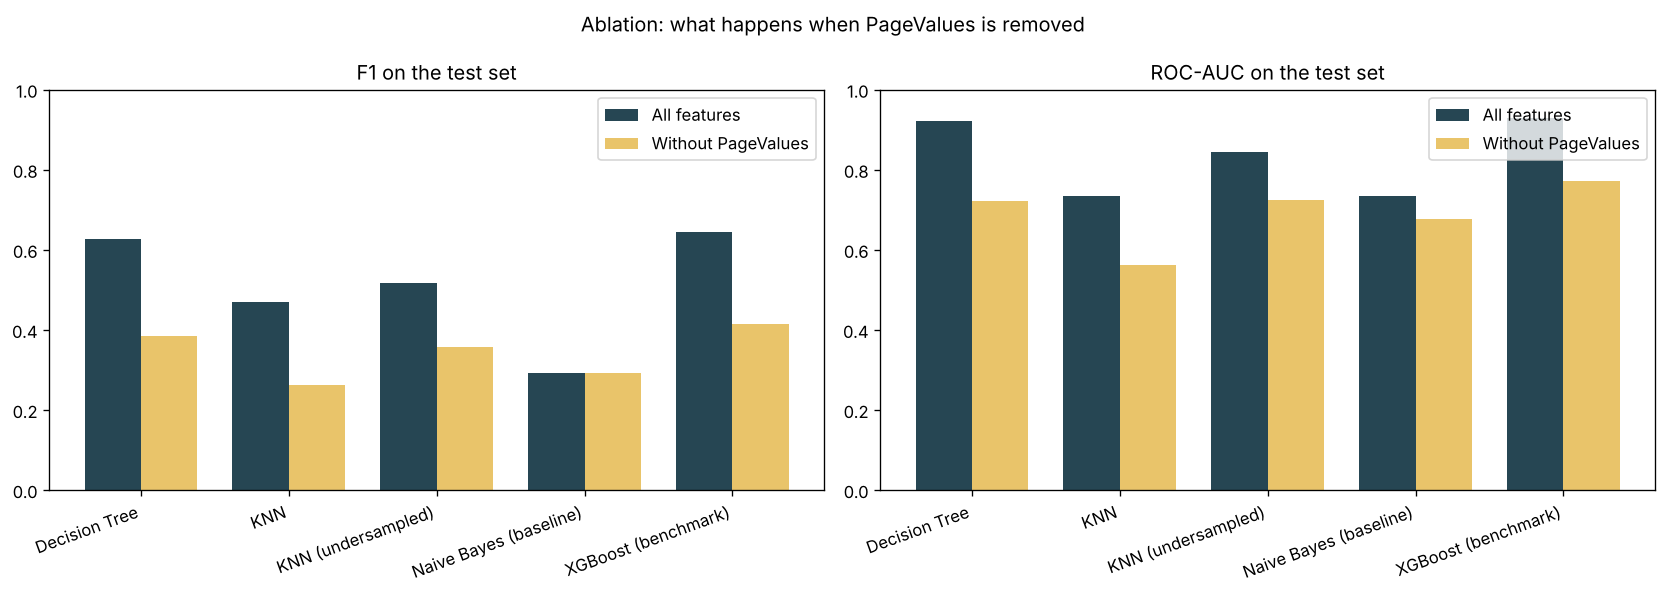

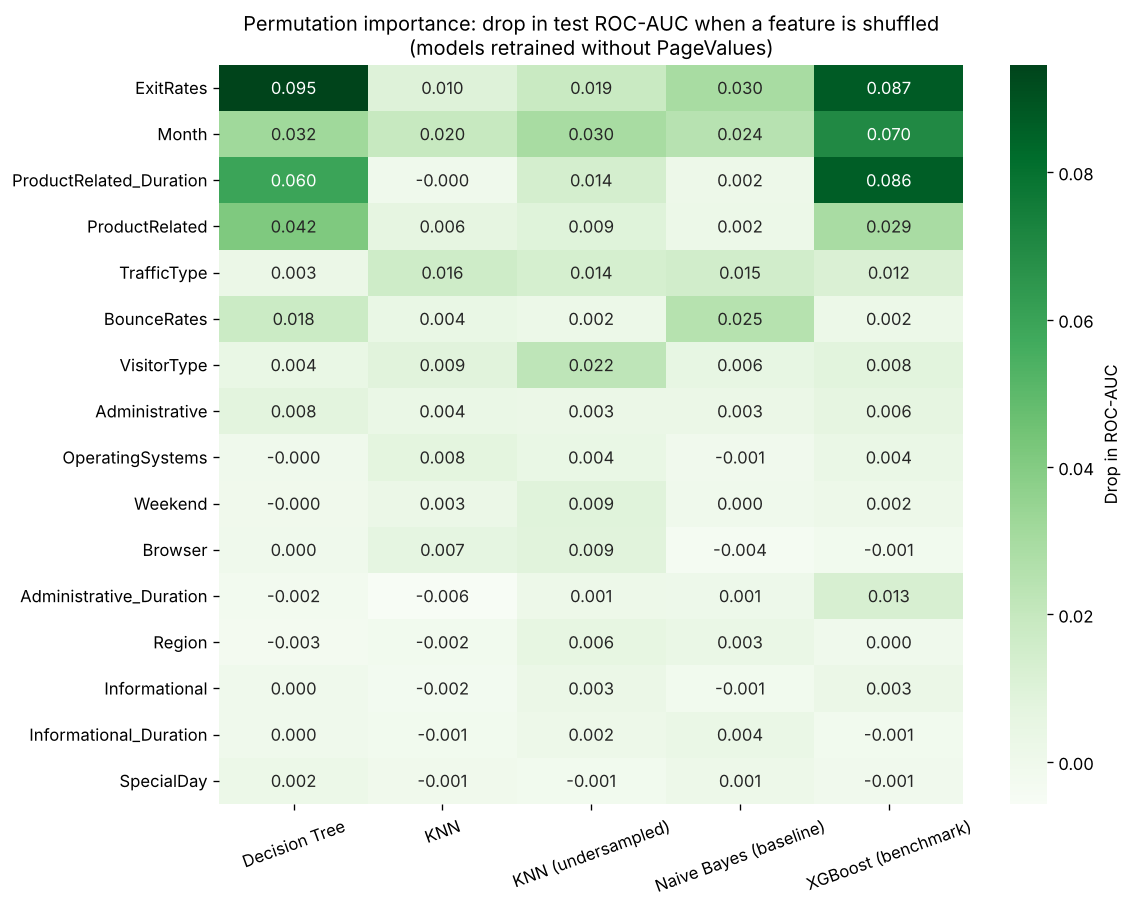

,Model,F1 (all features),F1 (no PageValues),ROC-AUC (all features),ROC-AUC (no PageValues),F1 change,ROC-AUC change
0,Decision Tree,0.627,0.384,0.922,0.721,-0.243,-0.201
1,KNN,0.469,0.261,0.734,0.562,-0.208,-0.172
2,KNN (undersampled),0.517,0.356,0.843,0.723,-0.161,-0.120
3,Naive Bayes (baseline),0.293,0.292,0.733,0.678,-0.001,-0.055
4,XGBoost (benchmark),0.645,0.414,0.929,0.772,-0.231,-0.157


In [10]:
ablation = run_ablation(train_features, train_target, test_features, test_target,
                        comparison_table, importance_table)
show("outputs/figures/ablation_scores.png")
show("outputs/figures/ablation_permutation_importance.png", width=750)
ablation["metrics"]

Without PageValues the Decision Tree, KNN and XGBoost lose roughly a third or more of their F1 (Naive Bayes barely changes, because it was already flagging almost every session), and the rankings reshuffle: the models fall back on **Month**, **ExitRates/BounceRates** and **product-page activity**. Those behaviour signals carry some information, but none replaces PageValues.

## 9. Choosing the decision threshold with a business goal

The default 0.5 cutoff is arbitrary. Suppose the shop sends a discount offer to every session the model flags. Using the illustrative assumptions at the top of the next cell (order profit, offer cost, and the share of a buyer's profit the offer secures):

- **true positive**: secured profit minus the offer cost
- **false positive**: the offer cost is wasted
- **false negative**: a missed sale (no extra profit)

We sweep thresholds from 0.01 to 0.99 on the out-of-fold training predictions, pick the best-F1 and best-profit thresholds, and compare them with 0.5 on the test set.


Tuning decision thresholds (business angle)...
  Assumptions: order profit $60, offer cost $6, offer conversion boost 40%
  Profit per true positive: $18.00, per false positive: $-6.00



Threshold comparison on the test set (2466 sessions):
                 Model Threshold type  Threshold  Precision  Recall    F1  Sessions targeted  Profit ($)
         Decision Tree    Default 0.5       0.50      0.512   0.806 0.627                601      3786.0
         Decision Tree        Best F1       0.76      0.681   0.641 0.660                360      3720.0
         Decision Tree    Best profit       0.70      0.611   0.715 0.659                447      3870.0
                   KNN    Default 0.5       0.50      0.576   0.395 0.469                262      2052.0
                   KNN        Best F1       0.35      0.504   0.442 0.471                335      2046.0
                   KNN    Best profit       0.35      0.504   0.442 0.471                335      2046.0
    KNN (undersampled)    Default 0.5       0.50      0.401   0.728 0.517                694      2508.0
    KNN (undersampled)        Best F1       0.53      0.433   0.694 0.533                612      2688.0


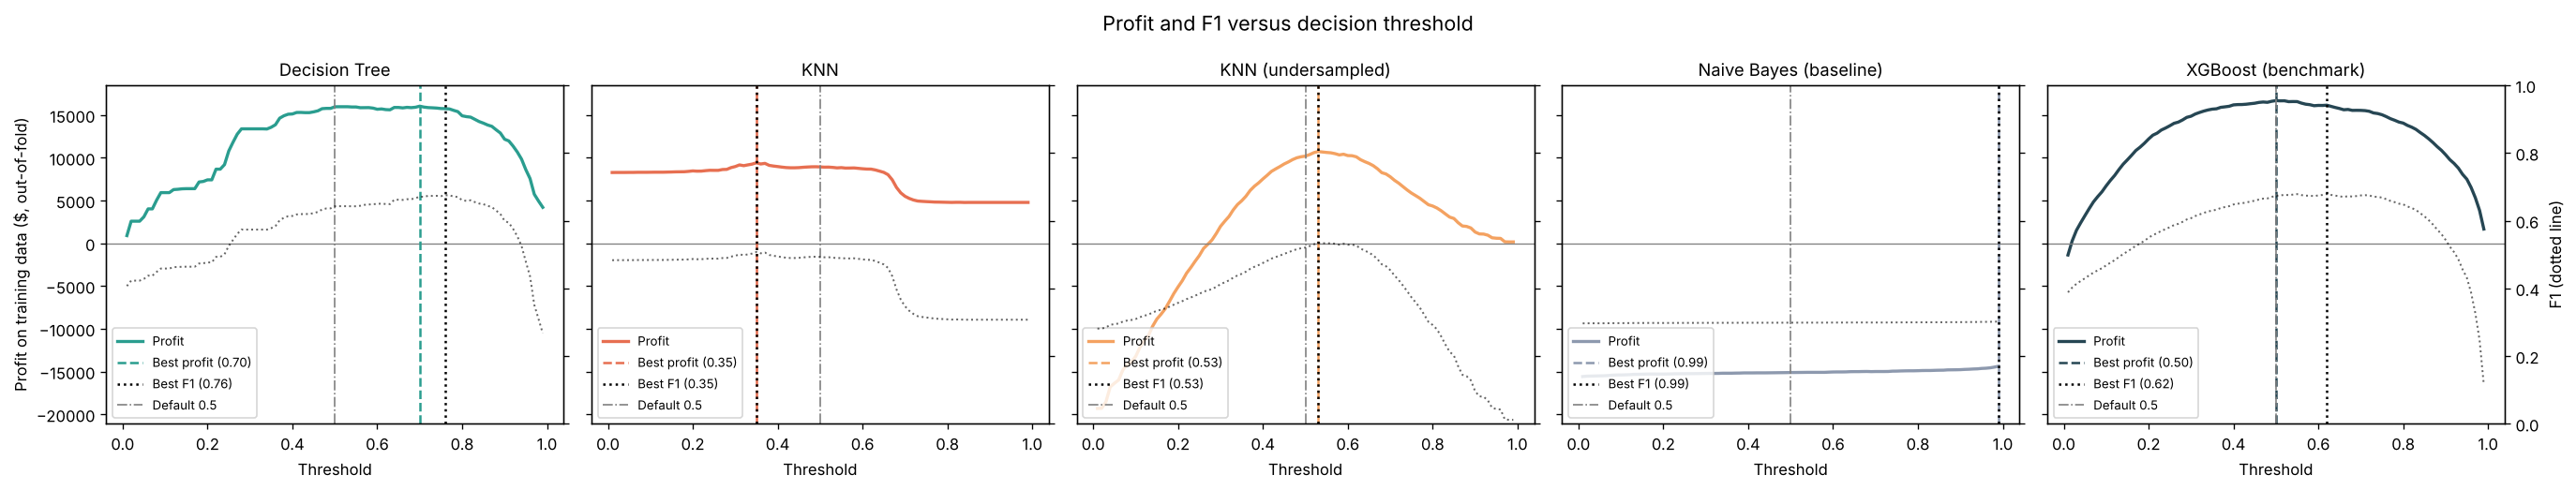

,Model,Threshold type,Threshold,Precision,Recall,F1,Sessions targeted,Profit ($)
0,Decision Tree,Default 0.5,0.50,0.512,0.806,0.627,601,3786.0
1,Decision Tree,Best F1,0.76,0.681,0.641,0.660,360,3720.0
2,Decision Tree,Best profit,0.70,0.611,0.715,0.659,447,3870.0
3,KNN,Default 0.5,0.50,0.576,0.395,0.469,262,2052.0
4,KNN,Best F1,0.35,0.504,0.442,0.471,335,2046.0
5,KNN,Best profit,0.35,0.504,0.442,0.471,335,2046.0
6,KNN (undersampled),Default 0.5,0.50,0.401,0.728,0.517,694,2508.0
7,KNN (undersampled),Best F1,0.53,0.433,0.694,0.533,612,2688.0
8,KNN (undersampled),Best profit,0.53,0.433,0.694,0.533,612,2688.0
9,Naive Bayes (baseline),Default 0.5,0.50,0.173,0.974,0.293,2155,-4002.0


In [11]:
from predator.threshold import tune_thresholds, plot_profit_curves

threshold_table, chosen_thresholds, training_curves = tune_thresholds(
    models, training_results, train_target, test_features, test_target)
show(plot_profit_curves(training_curves, chosen_thresholds))
threshold_table

The best threshold depends on the model's probability calibration as much as on the business numbers. The class-weighted Decision Tree, for example, pushes probabilities upwards, so its best-profit threshold sits well above 0.5. Naive Bayes loses money at every threshold, another sign its probabilities cannot be trusted. Change the assumptions and re-run to see the thresholds move.

## 10. Error analysis: who does the best model get wrong?

We label every test session as a caught buyer, missed buyer, false alarm or correct non-buyer (using the best model at its best-profit threshold) and compare the groups.


Error analysis of XGBoost (benchmark) at threshold 0.50...

Average feature values per group:
                        sessions  PageValues  share with PageValues = 0  ProductRelated_Duration  ExitRates  BounceRates  probability
group                                                                                                                                
Caught buyer (TP)            302      31.605                      0.066                 2176.859      0.019        0.004        0.862
Missed buyer (FN)             80       1.047                      0.800                 1470.466      0.033        0.014        0.286
False alarm (FP)             252      15.982                      0.254                 2294.236      0.022        0.007        0.721
Correct non-buyer (TN)      1832       0.176                      0.972                  913.720      0.049        0.027        0.093



# Error analysis: XGBoost (benchmark) (threshold 0.50)

| Group | Sessions | Mean PageValues | Share with PageValues = 0 | Median product time (s) | Mean ExitRates | Mean probability |
|---|---|---|---|---|---|---|
| Caught buyer (TP) | 302 | 31.6 | 7% | 1148 | 0.019 | 0.86 |
| Missed buyer (FN) | 80 | 1.0 | 80% | 781 | 0.033 | 0.29 |
| False alarm (FP) | 252 | 16.0 | 25% | 1662 | 0.022 | 0.72 |
| Correct non-buyer (TN) | 1832 | 0.2 | 97% | 424 | 0.049 | 0.09 |

## What the missed buyers have in common

- **They look like browsers, not buyers.** 80% of missed buyers have PageValues = 0, against 7% of caught buyers. PageValues is the model's strongest signal, so a buyer who never passed through a page linked to earlier purchases gets a low probability (mean 0.29).
- **Less engagement.** Their median time on product pages is 781 s, against 1148 s for caught buyers, and their mean exit rate is higher (0.033 vs 0.019).
- **Visitor type is not the reason.** 22% of missed buyers are new vis

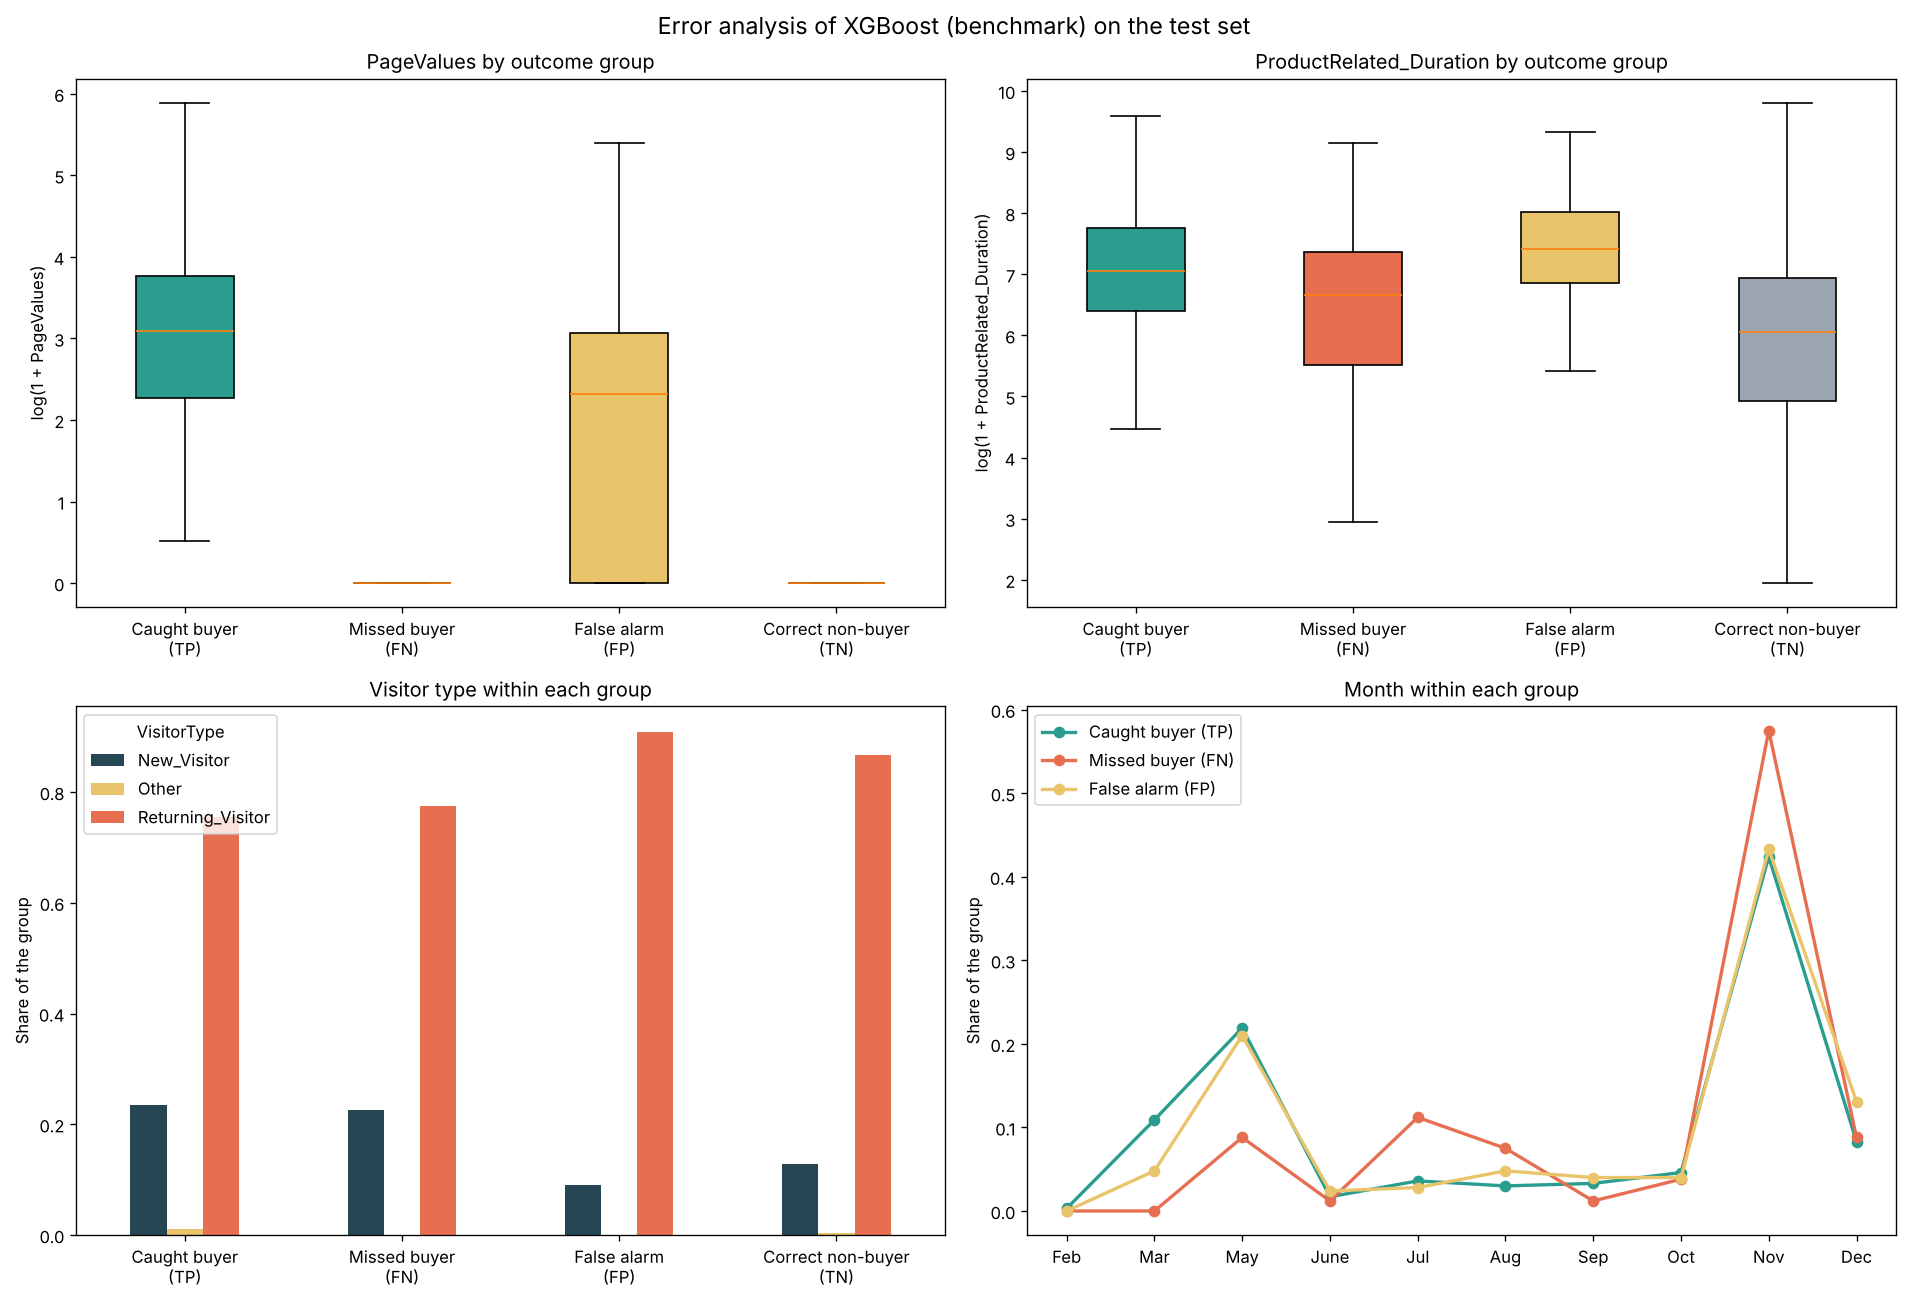

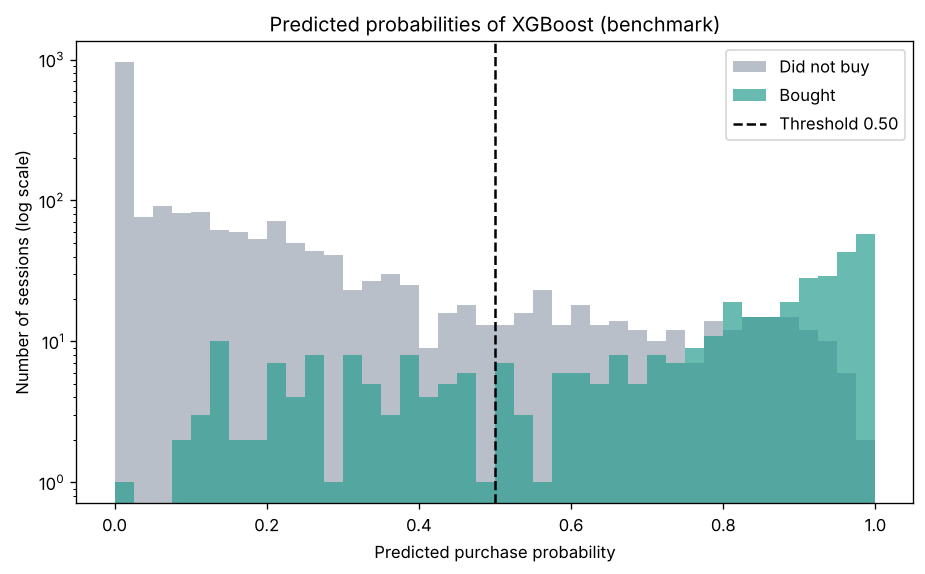

# Error analysis: XGBoost (benchmark) (threshold 0.50)

| Group | Sessions | Mean PageValues | Share with PageValues = 0 | Median product time (s) | Mean ExitRates | Mean probability |
|---|---|---|---|---|---|---|
| Caught buyer (TP) | 302 | 31.6 | 7% | 1148 | 0.019 | 0.86 |
| Missed buyer (FN) | 80 | 1.0 | 80% | 781 | 0.033 | 0.29 |
| False alarm (FP) | 252 | 16.0 | 25% | 1662 | 0.022 | 0.72 |
| Correct non-buyer (TN) | 1832 | 0.2 | 97% | 424 | 0.049 | 0.09 |

## What the missed buyers have in common

- **They look like browsers, not buyers.** 80% of missed buyers have PageValues = 0, against 7% of caught buyers. PageValues is the model's strongest signal, so a buyer who never passed through a page linked to earlier purchases gets a low probability (mean 0.29).
- **Less engagement.** Their median time on product pages is 781 s, against 1148 s for caught buyers, and their mean exit rate is higher (0.033 vs 0.019).
- **Visitor type is not the reason.** 22% of missed buyers are new visitors, about the same as caught buyers (24%).
- **Timing.** Nov is over-represented: 57% of missed buyers against 42% of caught buyers.

## What the false alarms have in common

- They look like buyers: mean PageValues 16.0 (caught buyers: 31.6) and only 25% have PageValues = 0. They reached valuable pages and then left without paying, which the features cannot tell apart from a purchase.
- 91% of false alarms are returning visitors, against 76% of caught buyers: people who come back, browse valuable pages and still do not buy.
- Dec is over-represented: 13% of false alarms against 8% of caught buyers.

## Why the model struggles

The dataset records how a session behaved, not why. A buyer who already knew what to buy can arrive, buy quickly and leave, without the page-value trail that most buyers leave. And a visitor who filled a cart and abandoned it leaves exactly that trail. With PageValues as the dominant feature, the model's mistakes are mostly the sessions where PageValues points the wrong way. More data about the visitor (past orders, cart contents) would be needed to fix them; tuning the model further cannot.


In [12]:
from predator.errors import run_error_analysis

best_threshold = chosen_thresholds[best_model_name]["best_profit"]
labelled_sessions = run_error_analysis(models[best_model_name], best_model_name,
                                       test_features, test_target, best_threshold)
show("outputs/figures/error_analysis.png")
show("outputs/figures/error_probability_histogram.png", width=650)
display(Markdown(open("outputs/error_analysis.md").read()))

## 11. Conclusions

- **PageValues is the deciding signal.** Every model ranks it first, the Decision Tree splits on it at the root, and removing it costs every model a large share of its F1.
- **The Decision Tree is the best main model.** It comes close to the XGBoost benchmark while staying fully readable, which matters when a shop team has to trust the rules.
- **XGBoost is the strongest benchmark**, a little ahead on F1 and ROC-AUC, at the price of interpretability.
- **KNN and Naive Bayes do not fit this data well.** KNN suffers from many one-hot dimensions and skewed features (undersampling helps); Naive Bayes' independence assumption breaks and its probabilities are unusable.
- **The threshold is a business decision.** With a profit model, the best cutoff differs from 0.5 and from the best-F1 cutoff, and it depends on the assumptions.
- **Missed buyers are mostly sessions with PageValues = 0**, which look like ordinary browsing; false alarms are mostly returning visitors who reached valuable pages and left. Fixing them needs more data about the visitor, not more tuning.

> This walkthrough imports the code from the `predator/` package. Run `python main.py` for the same pipeline in one command, and `streamlit run app.py` for the demo app.